<a href="https://colab.research.google.com/github/panarisivalentino-pixel/prediccion-rendimiento-agricola-argentina/blob/main/notebooks/08_red_neuronal_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizaje profundo: red neuronal (MLP) para el rendimiento agrícola (kg/ha)

**Variable objetivo:** `rendimiento_kgxha`
**Dataset:** `df_recortado.csv` (el mismo de los dos notebooks anteriores)

Este notebook corresponde a la **Unidad 4: Aprendizaje Automático Moderno** (redes neuronales / aprendizaje
profundo) y es un **complemento** del notebook supervisado: usa exactamente la misma preparación de datos,
el mismo split y las mismas métricas, para poder comparar una red neuronal contra los cinco modelos ya
entrenados (Regresión Lineal, Ridge, Random Forest, LightGBM y Gradient Boosting) bajo reglas idénticas.

**Pregunta que responde este notebook:** *¿una red neuronal mejora, empata o pierde contra los modelos de
árboles en este problema, y por qué?*

**Estructura**
1. Preparación de datos (idéntica al notebook supervisado)
2. Fundamento teórico: qué es un MLP y por qué probarlo acá
3. Arquitectura de la red y justificación de hiperparámetros
4. Entrenamiento y curva de pérdida
5. Evaluación en kg/ha
6. Comparación con los modelos del notebook supervisado
7. ¿Qué aprendió la red? Importancia por permutación
8. Conclusión

## 1. Preparación de datos

Esta sección es **idéntica** a la sección 1 del notebook supervisado: mismas variables, mismas variables
derivadas, mismo filtro de filas sin cosecha, mismo target en `log1p`, mismo split 80/20 estratificado por
`cultivo` con `random_state = SEED`, y la misma función `preparar()` (one-hot para `cultivo`/`provincia`,
target encoding para `departamento`, imputación con la mediana de train). Repetirla acá hace que este
notebook sea autocontenido y que la comparación final sea justa: la red neuronal ve exactamente los mismos
datos que vieron los otros cinco modelos.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import warnings, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
pd.options.display.float_format = '{:,.3f}'.format

df = pd.read_csv('/content/drive/MyDrive/Proyecto Agro (Grupo 1)/Colabs/data/df_recortado.csv')
print('Dimensiones:', df.shape)

Dimensiones: (111417, 17)


In [ ]:
# --- Limpieza mínima y variables derivadas (igual que en el notebook supervisado) ---
n0 = len(df)
df = df[df['superficie_cosechada_ha'] > 0].copy()
print(f'Filas sin cosecha excluidas: {n0-len(df):,}  →  filas para modelado: {len(df):,}')

df['ALLSKY_SFC_SW_DWN'] = df['ALLSKY_SFC_SW_DWN'].replace(0, np.nan)
df['log_sup_sembrada']  = np.log1p(df['superficie_sembrada_ha'])
df['log_sup_cosechada'] = np.log1p(df['superficie_cosechada_ha'])
df['ratio_cosechada']   = (df['superficie_cosechada_ha'] / df['superficie_sembrada_ha'].replace(0, np.nan)).clip(upper=1.5)
df['amplitud_termica']  = df['T2M_MAX'] - df['T2M_MIN']

CAT_OHE = ['cultivo', 'provincia']
CAT_TE  = ['departamento']
NUM     = ['año', 'log_sup_sembrada', 'log_sup_cosechada', 'ratio_cosechada',
           'T2M', 'T2M_MAX', 'T2M_MIN', 'amplitud_termica', 'ALLSKY_SFC_SW_DWN', 'RH2M', 'precip_total_mm']
TARGET  = 'rendimiento_kgxha'

X = df[CAT_OHE + CAT_TE + NUM]
y = df[TARGET]
y_log = np.log1p(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_log, test_size=0.20, random_state=SEED, stratify=X['cultivo'])
print(f'Train: {X_train.shape[0]:,} filas  |  Test: {X_test.shape[0]:,} filas')

Filas sin cosecha excluidas: 6,969  →  filas para modelado: 104,448
Train: 83,558 filas  |  Test: 20,890 filas


In [ ]:
def preparar(X_tr, X_te, y_tr):
    '''Codifica y prepara matrices. Todo se ajusta con el set de entrenamiento.'''
    Xtr = pd.get_dummies(X_tr, columns=CAT_OHE, dtype=float)
    Xte = pd.get_dummies(X_te, columns=CAT_OHE, dtype=float).reindex(columns=Xtr.columns, fill_value=0.0)
    te = TargetEncoder(target_type='continuous', cv=5, random_state=SEED)
    Xtr['departamento'] = te.fit_transform(X_tr[CAT_TE], y_tr)[:, 0]
    Xte['departamento'] = te.transform(X_te[CAT_TE])[:, 0]
    med = Xtr.median()
    return Xtr.fillna(med), Xte.fillna(med)

Xtr, Xte = preparar(X_train, X_test, y_train)
print('Matriz final de entrenamiento:', Xtr.shape, '| prueba:', Xte.shape)

Matriz final de entrenamiento: (83558, 76) | prueba: (20890, 76)


In [ ]:
resultados = {}   # nombre -> dict de métricas
modelos    = {}   # nombre -> modelo ajustado
preds_test = {}   # nombre -> predicciones (kg/ha) sobre test

def metricas(y_true_log, y_pred_log):
    yt, yp = np.expm1(y_true_log), np.expm1(np.clip(y_pred_log, 0, 14))
    return dict(MAE=mean_absolute_error(yt, yp), RMSE=np.sqrt(mean_squared_error(yt, yp)), R2=r2_score(yt, yp))

def evaluar(nombre, modelo, Xtr=Xtr, Xte=Xte):
    t0 = time.time(); modelo.fit(Xtr, y_train); t = time.time() - t0
    m_tr = metricas(y_train, modelo.predict(Xtr)); m_te = metricas(y_test, modelo.predict(Xte))
    resultados[nombre] = {'MAE train': m_tr['MAE'], 'RMSE train': m_tr['RMSE'], 'R² train': m_tr['R2'],
                          'MAE test': m_te['MAE'], 'RMSE test': m_te['RMSE'], 'R² test': m_te['R2'], 'Tiempo (s)': t}
    modelos[nombre] = modelo; preds_test[nombre] = np.expm1(modelo.predict(Xte))
    fila = pd.DataFrame(resultados[nombre], index=[nombre])
    display(fila.style.format({'MAE train':'{:,.0f}','RMSE train':'{:,.0f}','MAE test':'{:,.0f}','RMSE test':'{:,.0f}',
                               'R² train':'{:.4f}','R² test':'{:.4f}','Tiempo (s)':'{:.1f}'}))
    return modelo

## 2. Fundamento teórico: qué es un MLP y por qué probarlo acá

**Qué es.** Un *Multi-Layer Perceptron* (MLP) encadena varias capas de neuronas. Cada neurona hace una
combinación lineal de sus entradas (como una mini regresión lineal) y le aplica una función de activación
no lineal (ReLU). Apilar varias capas permite aprender combinaciones de combinaciones, lo que en teoría le
da a la red la capacidad de aproximar **cualquier función continua**, incluyendo curvas con umbrales como
las que encontramos con SHAP en el notebook supervisado (por ejemplo, el quiebre del efecto de `T2M` por
encima de ~20 °C).

**Por qué probarlo en este problema.** El objetivo de esta sección no es necesariamente superar a LightGBM,
sino **verificar empíricamente** una afirmación bien conocida en la literatura: en datos **tabulares**
(filas y columnas con variables heterogéneas, como las nuestras: categóricas, climáticas, de superficie),
los modelos de árboles/boosting suelen igualar o superar a las redes neuronales, mientras que estas últimas
dominan en dominios con estructura espacial o secuencial (imágenes, texto, audio). Este notebook pone esa
afirmación a prueba con nuestros propios datos.

**Alternativa considerada y descartada.** Se podría construir la red con TensorFlow/Keras o PyTorch, lo que
daría más control (callbacks, arquitecturas más ricas, regularización más fina). Se elige `MLPRegressor` de
scikit-learn porque se integra directo en el mismo `Pipeline` y en la misma función `evaluar()` que ya
usamos para los otros cinco modelos, lo que mantiene la comparación limpia y el código consistente con el
resto del proyecto. Si en el futuro se buscara exprimir más precisión, Keras sería el paso siguiente.

## 3. Arquitectura de la red y justificación de hiperparámetros

**Preprocesamiento.** Igual que la regresión lineal y Ridge, el MLP es sensible a la escala de las variables
(una variable en cientos de mm pesaría más que una variable en decenas de °C si no se escalan). Por eso va
encapsulado en un `Pipeline` con `StandardScaler`, igual que los modelos lineales.

**Hiperparámetros elegidos:**
- `hidden_layer_sizes = (64, 32)`: dos capas ocultas. La primera (64 neuronas) tiene espacio suficiente para
  detectar patrones variados sobre las 76 columnas de entrada; la segunda (32) combina esos patrones en
  representaciones más compactas. Es una arquitectura chica a propósito: con ~84.000 filas de entrenamiento,
  una red mucho más grande tendría alto riesgo de sobreajuste y de necesitar muchas más épocas para converger.
- `activation = 'relu'`: la activación estándar; evita el problema de gradientes que se desvanecen que tienen
  activaciones más antiguas como la sigmoide.
- `alpha = 1e-3`: penalización L2 sobre los pesos (el equivalente del `alpha` de Ridge), para evitar que la
  red memorice.
- `solver = 'adam'`: el optimizador de descenso de gradiente más usado en la práctica; ajusta el tamaño de
  paso de forma adaptativa por cada peso.
- `learning_rate_init = 1e-3`: el tamaño de paso inicial de Adam; un valor estándar.
- `max_iter = 400` y `early_stopping = True` (con `n_iter_no_change = 15`): se entrena hasta 400 épocas, pero
  se detiene antes si el error de validación interna no mejora durante 15 épocas seguidas. Esto evita
  sobreajuste y ahorra tiempo de cómputo, cumpliendo un rol parecido al de limitar `max_depth` en un árbol.

**Complejidad.** El costo de entrenar un MLP con backpropagation es, por época, proporcional al número de
pesos de la red multiplicado por el número de filas. Con dos capas de 64 y 32 neuronas sobre 76 variables de
entrada, la red tiene unos pocos miles de pesos: mucho menos que los cientos de árboles de Random Forest o
LightGBM, pero cada peso se ajusta de forma iterativa y gradual, por lo que el tiempo total depende fuerte
de cuántas épocas hagan falta hasta que `early_stopping` corte el entrenamiento.

In [ ]:
mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu', alpha=1e-3,
                 solver='adam', learning_rate_init=1e-3, max_iter=400,
                 early_stopping=True, n_iter_no_change=15, random_state=SEED)
)
mlp = evaluar('MLP (red neuronal)', mlp)

,MAE train,RMSE train,R² train,MAE test,RMSE test,R² test,Tiempo (s)
MLP (red neuronal),661,"1,720",0.8964,687,"1,531",0.9164,133.9


### 3.1 Esquema de la arquitectura

Este gráfico es un **esquema**, no usa los pesos aprendidos: muestra la estructura que definimos en el
código (cuántas capas, cuántas neuronas por capa, cómo se conectan todas con todas entre capas consecutivas).
Es el diagrama que conviene mostrar en la exposición para explicar visualmente lo que la sección 3 describe
en texto. Como la capa de entrada tiene 76 variables y la primera oculta 64 neuronas, dibujar cada una
individualmente sería ilegible: se muestra una **muestra representativa** por capa, con puntos suspensivos
indicando las que se omiten, y la cantidad real aclarada debajo de cada capa.

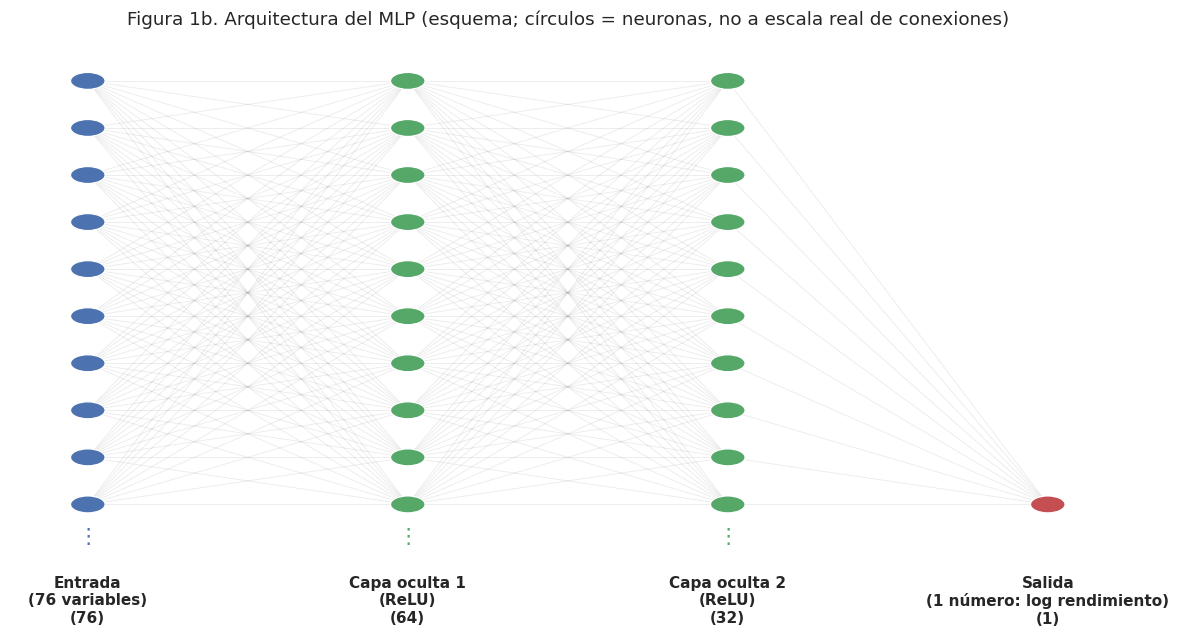

In [ ]:
import matplotlib.patches as mpatches

def graficar_arquitectura(capas, nombres, max_mostrar=10):
    '''Dibuja un esquema de una red feedforward. `capas`: lista con el tamaño real de cada capa.
    `nombres`: etiqueta de cada capa. Solo se dibujan hasta `max_mostrar` neuronas por capa (con "..." si hay más).'''
    fig, ax = plt.subplots(figsize=(11, 6))
    x_capas = np.linspace(0, 1, len(capas))
    posiciones = []

    for xi, n in zip(x_capas, capas):
        n_dibujar = min(n, max_mostrar)
        ys = np.linspace(0.05, 0.95, n_dibujar)
        posiciones.append(list(zip([xi]*n_dibujar, ys)))

    # Conexiones (todas con todas, entre capas consecutivas)
    for p1, p2 in zip(posiciones[:-1], posiciones[1:]):
        for (x1, y1) in p1:
            for (x2, y2) in p2:
                ax.plot([x1, x2], [y1, y2], color='gray', alpha=0.15, lw=0.6, zorder=1)

    colores = ['#4C72B0', '#55A868', '#55A868', '#C44E52']
    for i, (xi, pos, n, nombre) in enumerate(zip(x_capas, posiciones, capas, nombres)):
        color = colores[min(i, len(colores)-1)]
        for (x, y) in pos:
            ax.add_patch(mpatches.Circle((x, y), 0.018, color=color, zorder=2, ec='white', lw=0.8))
        if n > max_mostrar:
            ax.text(xi, -0.03, '⋮', ha='center', fontsize=14, color=color)
        ax.text(xi, -0.10, f'{nombre}\n({n})', ha='center', va='top', fontsize=10, fontweight='bold')

    ax.set_xlim(-0.08, 1.08); ax.set_ylim(-0.18, 1.05); ax.axis('off')
    ax.set_title('Figura 1b. Arquitectura del MLP (esquema; círculos = neuronas, no a escala real de conexiones)')
    plt.tight_layout(); plt.show()

n_entrada = Xtr.shape[1]
graficar_arquitectura(
    capas=[n_entrada, 64, 32, 1],
    nombres=['Entrada\n(76 variables)', 'Capa oculta 1\n(ReLU)', 'Capa oculta 2\n(ReLU)', 'Salida\n(1 número: log rendimiento)']
)

**Cómo leer el esquema:** cada línea gris representa una conexión con un peso que la red ajustó durante
el entrenamiento (sección 5, backpropagation). En la capa de entrada real hay 76 variables (no 10), y en la
primera capa oculta hay 64 neuronas (no 10): se muestran recortadas solo para que el dibujo sea legible. Lo
importante para la exposición es la **idea de conectividad total entre capas consecutivas**, no el número
exacto de líneas dibujadas.

## 4. Curva de pérdida: diagnóstico del entrenamiento

A diferencia de un árbol (que se construye de una vez), la red se ajusta de a poco, época por época. La
**curva de pérdida** muestra cómo bajó el error de entrenamiento en cada época. Es el equivalente, para una
red neuronal, de las *learning curves* que usamos para los modelos de árboles en el notebook supervisado,
solo que acá el eje X son épocas de entrenamiento y no cantidad de datos.

**Cómo leerla:**
- Si la curva baja y se **aplana** antes de llegar a `max_iter`: la red convergió y `early_stopping` hizo
  bien su trabajo.
- Si la curva **sigue bajando** fuerte al cortar: convendría permitir más épocas (`max_iter` más alto).
- Si la curva es **muy ruidosa** (sube y baja todo el tiempo): el `learning_rate_init` puede ser demasiado
  alto para este problema.

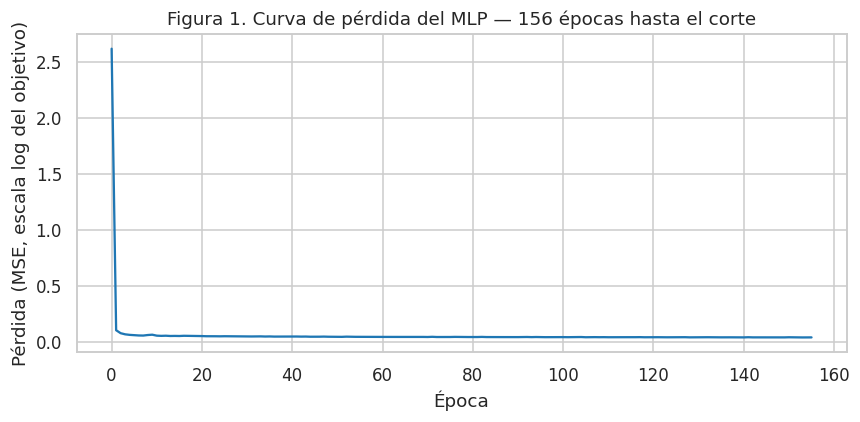

Épocas totales: 156  |  Pérdida final: 0.0410


In [ ]:
loss_curve = mlp.named_steps['mlpregressor'].loss_curve_
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(loss_curve, color='tab:blue')
ax.set_xlabel('Época'); ax.set_ylabel('Pérdida (MSE, escala log del objetivo)')
ax.set_title(f'Figura 1. Curva de pérdida del MLP — {len(loss_curve)} épocas hasta el corte')
plt.tight_layout(); plt.show()
print(f'Épocas totales: {len(loss_curve)}  |  Pérdida final: {loss_curve[-1]:.4f}')

## 5. Evaluación en kg/ha

Las métricas de la sección 3 (tabla de `evaluar`) ya están en kg/ha, gracias a `metricas()`, que deshace la
transformación log con `expm1` — la misma función que usamos en el notebook supervisado. Acá solo
completamos el diagnóstico con un gráfico de real vs. predicho sobre el conjunto de prueba, igual al de la
Figura 8 del notebook supervisado, para poder comparar visualmente el comportamiento de la red con el de
LightGBM.

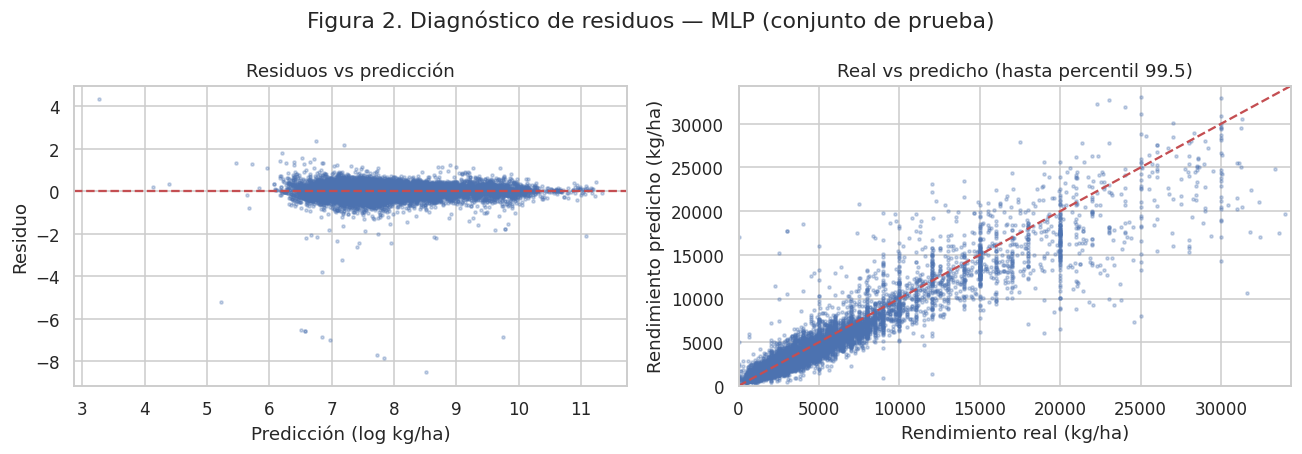

In [ ]:
pred_log = mlp.predict(Xte)
yt, yp = np.expm1(y_test), np.expm1(np.clip(pred_log, 0, 14))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
res = y_test - pred_log
ax[0].scatter(pred_log, res, s=4, alpha=.3); ax[0].axhline(0, color='r', ls='--')
ax[0].set_xlabel('Predicción (log kg/ha)'); ax[0].set_ylabel('Residuo'); ax[0].set_title('Residuos vs predicción')

lim = [0, np.percentile(yt, 99.5)]
ax[1].scatter(yt, yp, s=4, alpha=.3); ax[1].plot(lim, lim, 'r--'); ax[1].set_xlim(lim); ax[1].set_ylim(lim)
ax[1].set_xlabel('Rendimiento real (kg/ha)'); ax[1].set_ylabel('Rendimiento predicho (kg/ha)')
ax[1].set_title('Real vs predicho (hasta percentil 99.5)')
plt.suptitle('Figura 2. Diagnóstico de residuos — MLP (conjunto de prueba)'); plt.tight_layout(); plt.show()

## 6. Comparación con los modelos del notebook supervisado

Para comparar, se toman las métricas finales de los tres modelos de referencia tal como quedaron reportadas
en la sección 6.1 del notebook supervisado (no se reentrenan acá, para no duplicar cómputo): el modelo base
(Regresión Lineal), el mejor modelo de bagging (Random Forest) y el modelo ganador (LightGBM optimizado). Se
arma una única tabla con esos tres más el MLP recién entrenado, bajo las mismas métricas y el mismo split.

,MAE test,RMSE test,R² test,Tiempo (s)
Random Forest (inicial),484,"1,280",0.9420,105.0
LightGBM (opt) — ganador,500,"1,276",0.9420,7.0
MLP (red neuronal),687,"1,531",0.9164,133.9
Regresión Lineal (base),"1,020","2,243",0.8210,0.4


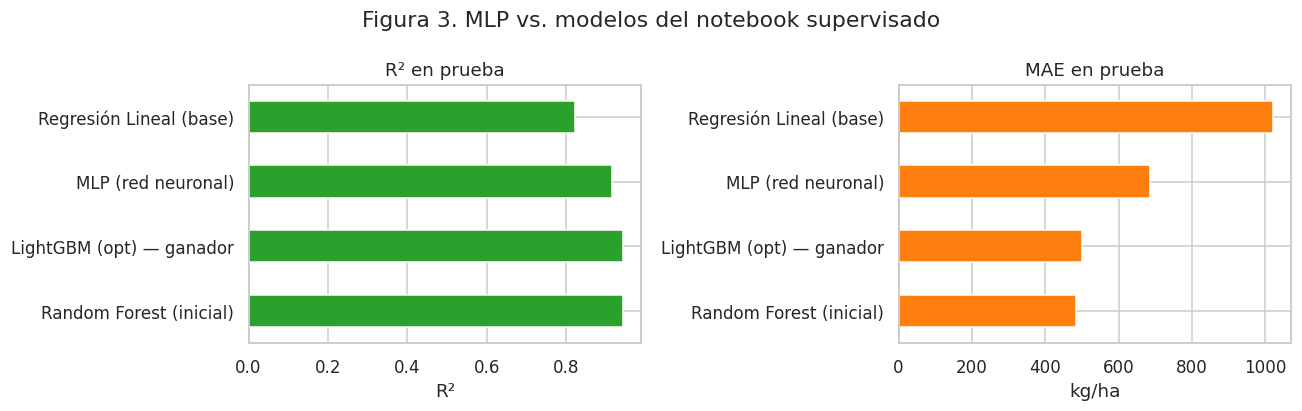

In [ ]:
referencia_supervisado = {
    'Regresión Lineal (base)':      {'MAE test': 1020, 'RMSE test': 2243, 'R² test': 0.821, 'Tiempo (s)': 0.4},
    'Random Forest (inicial)':      {'MAE test':  484, 'RMSE test': 1280, 'R² test': 0.942, 'Tiempo (s)': 105},
    'LightGBM (opt) — ganador':     {'MAE test':  500, 'RMSE test': 1276, 'R² test': 0.942, 'Tiempo (s)': 7},
}
fila_mlp = {'MAE test': resultados['MLP (red neuronal)']['MAE test'],
            'RMSE test': resultados['MLP (red neuronal)']['RMSE test'],
            'R² test': resultados['MLP (red neuronal)']['R² test'],
            'Tiempo (s)': resultados['MLP (red neuronal)']['Tiempo (s)']}
comparativa = pd.DataFrame({**referencia_supervisado, 'MLP (red neuronal)': fila_mlp}).T
comparativa = comparativa.sort_values('R² test', ascending=False)
display(comparativa.style.format({'MAE test':'{:,.0f}','RMSE test':'{:,.0f}','R² test':'{:.4f}','Tiempo (s)':'{:.1f}'})
        .background_gradient(subset=['R² test'], cmap='Greens'))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
comparativa['R² test'].plot.barh(ax=ax[0], color='tab:green'); ax[0].set_title('R² en prueba'); ax[0].set_xlabel('R²')
comparativa['MAE test'].plot.barh(ax=ax[1], color='tab:orange'); ax[1].set_title('MAE en prueba'); ax[1].set_xlabel('kg/ha')
plt.suptitle('Figura 3. MLP vs. modelos del notebook supervisado'); plt.tight_layout(); plt.show()

**Lectura (completar tras ejecutar).** Estas preguntas guían la lectura de la tabla y el gráfico de arriba;
respondelas con los números que te dé tu propia ejecución:

- ¿El R² del MLP quedó más cerca del de la Regresión Lineal o del de LightGBM? ¿Qué te dice eso sobre la
  capacidad de la red para capturar las interacciones no lineales que SHAP mostró en el notebook supervisado?
- Compará el tiempo de entrenamiento del MLP contra el de LightGBM. ¿La diferencia de precisión (si la hay)
  justifica la diferencia de tiempo?
- Si el R² del MLP quedó cerca de los árboles pero el MAE no, ¿qué te dice eso sobre *dónde* se concentran
  los errores de la red (pensá en la relación entre MAE y RMSE que vimos antes)?

## 7. ¿Qué aprendió la red? Importancia por permutación

Los árboles tienen importancia de variables "de fábrica" (impureza, ganancia) y LightGBM se presta bien a
SHAP. Una red neuronal no tiene un equivalente directo y simple: la información está repartida en miles de
pesos, sin una estructura de "divisiones" que interpretar. La alternativa **agnóstica al modelo** (sirve para
cualquier modelo, no solo redes) es la **importancia por permutación**:

1. Se mide el error del modelo ya entrenado sobre el conjunto de prueba (la referencia).
2. Se toma **una sola columna** (por ejemplo `precip_total_mm`) y se **desordenan sus valores al azar** entre
   las filas, rompiendo su relación con el resto de las variables y con el objetivo.
3. Se vuelve a medir el error con esa columna "arruinada".
4. Cuánto **empeora** el error es la importancia de esa variable: si apenas cambia, la red no la estaba
   usando mucho; si empeora fuerte, la variable era clave.
5. Se repite para cada columna (con varias repeticiones por columna, para promediar el ruido del
   desordenamiento al azar).

Es más costosa que la importancia de un árbol (hay que volver a predecir muchas veces), pero funciona igual
de bien para un MLP que para cualquier otro modelo.

,Importancia por permutación (normalizada)
cultivo (41 dummies),0.564
provincia (23 dummies),0.208
log_sup_cosechada,0.061
log_sup_sembrada,0.043
año,0.033
T2M,0.033
ratio_cosechada,0.013
RH2M,0.009
T2M_MIN,0.009
T2M_MAX,0.007


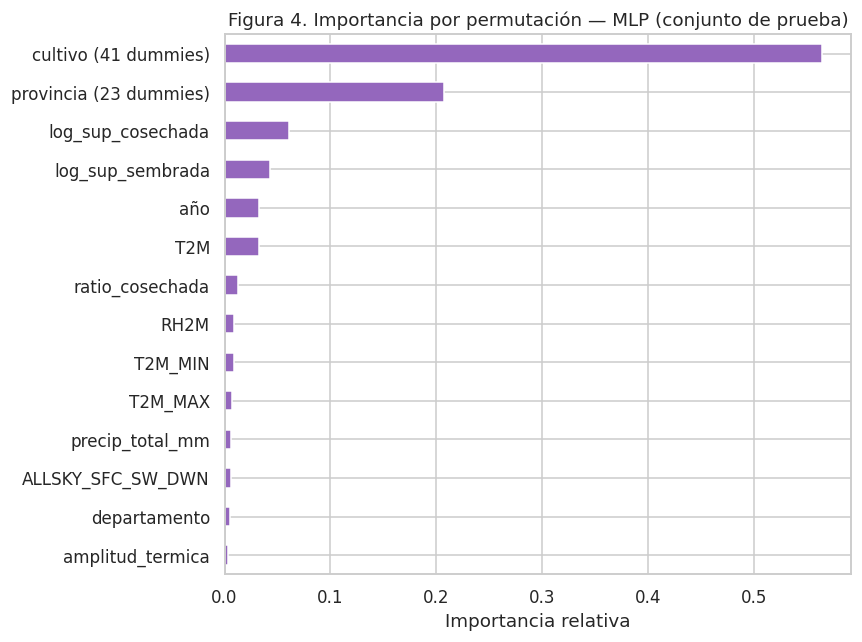

In [ ]:
def agrupar(imp, cols):
    '''Agrupa las dummies de cultivo y provincia en un solo valor por grupo (igual que en el notebook supervisado).'''
    s = pd.Series(imp, index=cols)
    g = s[~s.index.str.startswith(('cultivo_', 'provincia_'))].copy()
    g['cultivo (41 dummies)']   = s[s.index.str.startswith('cultivo_')].sum()
    g['provincia (23 dummies)'] = s[s.index.str.startswith('provincia_')].sum()
    return (g / g.abs().sum()).sort_values(ascending=False)

Xte_muestra = Xte.sample(3000, random_state=SEED)
y_muestra   = y_test.loc[Xte_muestra.index]

perm = permutation_importance(mlp, Xte_muestra, y_muestra, n_repeats=5,
                               scoring='r2', random_state=SEED, n_jobs=1)
imp_mlp = agrupar(perm.importances_mean, Xte.columns)

display(imp_mlp.round(3).to_frame('Importancia por permutación (normalizada)'))
imp_mlp.sort_values().plot.barh(figsize=(8, 6), color='tab:purple')
plt.xlabel('Importancia relativa'); plt.title('Figura 4. Importancia por permutación — MLP (conjunto de prueba)')
plt.tight_layout(); plt.show()

**Lectura (completar tras ejecutar).**
- ¿El orden de importancia del MLP se parece al que obtuviste con SHAP para LightGBM en el notebook
  supervisado (cultivo primero, después año, después clima)? Si es parecido, es una señal de que ambos
  modelos están aprendiendo la misma estructura real de los datos, aunque por caminos muy distintos.
- Si el orden es muy distinto, pensá: ¿puede deberse a que la red no entrenó lo suficiente (revisá la curva
  de pérdida de la sección 4), o a que de verdad "ve" el problema de otra forma?

## 8. Conclusión

Completá esta sección con los resultados de tu propia ejecución antes de la exposición; dejamos la
estructura y las preguntas guía, no los números (para no exponer en clase un resultado que no corre en tu
máquina).

**Resumen a completar:**
- R² en prueba del MLP: ___ (comparado con 0,942 de LightGBM y 0,821 de la Regresión Lineal)
- MAE en prueba del MLP: ___ kg/ha (comparado con 500 kg/ha de LightGBM)
- Tiempo de entrenamiento del MLP: ___ s (comparado con 7 s de LightGBM)

**Preguntas para redactar la conclusión:**
1. ¿La red neuronal superó, empató o perdió contra LightGBM? Con los fundamentos de la sección 2, ¿el
   resultado te sorprende o confirma lo esperado para datos tabulares?
2. ¿Qué ventaja concreta, si la hay, tendría usar una red neuronal en este problema en vez de LightGBM?
   (Pensá en términos de interpretabilidad, tiempo de entrenamiento, facilidad de ajuste, no solo precisión.)
3. Si tuvieras que mejorar la red para intentar acercarla más a LightGBM, ¿qué cambiarías primero:
   la arquitectura (más neuronas/capas), los hiperparámetros de regularización, o el tiempo de entrenamiento
   (`max_iter`)? Justificá con lo que viste en la curva de pérdida.
4. Conectando con el proyecto completo: ¿qué modelo recomendarías llevar a producción — el más preciso, el
   más rápido, o el más fácil de explicarle a un productor agropecuario? ¿Por qué no son necesariamente
   el mismo?